In [1]:
import numpy as np
import matplotlib.pyplot as plt

import essrs

In [2]:
N_MIX = 2
THETA = np.array([0.5])
MU = np.array([-3.0, 3.0])
SIGMA = np.array([0.5, 0.5])

In [3]:
N_SAMPLES: int = 1000
N_WALKERS: int = 10
N_PARAMETERS: int = 1
N_BURN_IN: int = 100
N_THREADS: int = 1
N_THINNING_PER_SAMPLE: int = None

In [4]:
# model = essrs.model.toy.normal_1d_mix(N_MIX, THETA, MU, SIGMA)

burn_move = essrs.moves.hybrid_ddc_move(one_in_n=10)
sampler_move = essrs.moves.differential_move()
config = essrs.EnsembleConfig(
    n_samples=N_SAMPLES,
    n_walkers=N_WALKERS,
    n_parameters=N_PARAMETERS,
    n_burn_in=N_BURN_IN,
    n_threads=N_THREADS,
    n_thinning_per_sample=5
)

In [5]:
ics = np.random.uniform(low=-5, high=5, size=(N_WALKERS, N_PARAMETERS))
print(ics)

[[ 2.77050331]
 [ 4.20887661]
 [ 0.51093657]
 [-3.48839526]
 [-1.63178607]
 [-2.87160879]
 [-3.10065772]
 [-2.20765157]
 [ 1.93051239]
 [ 2.19044004]]


In [6]:
# fit, ll = essrs.run_mcmc(
#     log_likelihood=model,
#     config=config,
#     burn_in_move=burn_move,
#     sampling_move=sampler_move,
#     initial_conditions=ics
# )

In [7]:
# plt.figure()
# plt.hist(fit.ravel(), bins=1000)
# plt.show()

In [8]:
model_a = essrs.model.toy.normal(MU[0], SIGMA[0])
model_b = essrs.model.toy.normal(MU[1], SIGMA[1])

model = essrs.model.toy.dyn_mixture_model(np.array([0.5]), [model_a, model_b])

INITIALISING
Physical:
[[2.77050330566184],
 [4.20887660574634],
 [0.5109365650660913],
 [-3.4883952559244333],
 [-1.631786066053209],
 [-2.871608787794604],
 [-3.1006577184762216],
 [-2.20765156512827],
 [1.9305123944647185],
 [2.190440035793526]], shape=[10, 1], strides=[1, 1], layout=CFcf (0xf), const ndim=2
Internal:
[[2.77050330566184],
 [4.20887660574634],
 [0.5109365650660913],
 [-3.4883952559244333],
 [-1.631786066053209],
 [-2.871608787794604],
 [-3.1006577184762216],
 [-2.20765156512827],
 [1.9305123944647185],
 [2.190440035793526]], shape=[10, 1], strides=[1, 1], layout=CFcf (0xf), const ndim=2


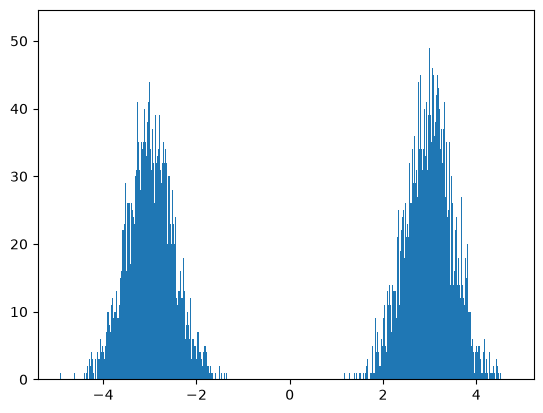

In [9]:
fit, ll = essrs.run_mcmc(
    log_likelihood=model,
    config=config,
    burn_in_move=burn_move,
    sampling_move=sampler_move,
    initial_conditions=ics
)
plt.figure()
plt.hist(fit.ravel(), bins=1000)
plt.show()